### **Customer Churn Prediction**

####**Project Overview**

The objective of this project is to analyze customer churn in a telecommunications company and develop a machine learning model that predicts whether a customer is likely to leave the company.

This project includes data cleaning, exploratory data analysis, data preprocessing, model comparison, hyperparameter tuning, model evaluation, and business recommendations.

The final model will also be deployed through a Streamlit web application, allowing users to enter customer details and receive churn predictions.

https://github.com/MuhammedSalmanAhmed/Customer-Churn-Project-PSEB/tree/main

In [44]:

# Import necessary libraries
import pandas as pd
import numpy as np

# Upload the dataset
from google.colab import files
uploaded = files.upload()

# Load the CSV file
df = pd.read_csv('telco_churn.csv')

# Display the first five rows
df.head()


Saving telco_churn.csv to telco_churn (1).csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#Initial Data Inspection

In [4]:

# Check dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Check data types and non-null values
print("\nDataset Information:")
df.info()


Number of Rows: 7043
Number of Columns: 21

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 n

In [5]:

# Check missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values: 0


In [6]:

# Check duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 0


In [7]:

# Check churn distribution
print("Churn Distribution:")
print(df['Churn'].value_counts())

# Check churn percentage
print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)


Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:

# Display unique values in categorical columns
for column in df.select_dtypes(include='object').columns:
    print(f"\n{column}:")
    print(df[column].unique())



customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

TotalCharges:
['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']

Churn:
['No' 'Yes']



## Initial Data Inspection

The dataset contains 7,043 rows and 21 columns. The initial inspection showed that there are no duplicate records and no explicitly detected missing values.

The dataset contains 18 object-type columns, 2 integer columns, and 1 floating-point column.

The target variable `Churn` contains two classes:
- No: 5,174 customers (73.46%)
- Yes: 1,869 customers (26.54%)

This indicates that the dataset is imbalanced because the majority of customers have not churned.

One issue identified during inspection is that the `TotalCharges` column is stored as an object rather than a numeric data type. We will address this during data cleaning.

The customer ID column will also be removed because it is an identifier and does not provide meaningful information for predicting customer churn.


#Data Cleaning

In [9]:

# Replace blank spaces with NaN
df['TotalCharges'] = df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True)

# Convert TotalCharges into numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

# Check missing values
print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())


Missing values in TotalCharges: 11


In [10]:

# Fill missing TotalCharges values with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

print("Missing Values After Cleaning:", df['TotalCharges'].isnull().sum())


Missing Values After Cleaning: 0


In [11]:

# Remove customerID column
df.drop('customerID', axis=1, inplace=True)

# Display updated dataset shape
print("Dataset Shape After Cleaning:", df.shape)


Dataset Shape After Cleaning: (7043, 20)


In [12]:

print("FINAL DATA CLEANING SUMMARY")
print("=" * 40)

print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)


FINAL DATA CLEANING SUMMARY
Dataset Shape: (7043, 20)
Total Missing Values: 0
Total Duplicate Rows: 22

Data Types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object



## Data Cleaning

Data cleaning was performed to prepare the dataset for machine learning.

First, the `TotalCharges` column was converted from object to numeric format. During this process, 11 blank values were identified and replaced with the median value of the column.

Next, the `customerID` column was removed because it is a unique customer identifier and does not contribute meaningful predictive information.

After cleaning, the dataset contains 7,043 rows and 20 columns, with no remaining missing values.


#EDA

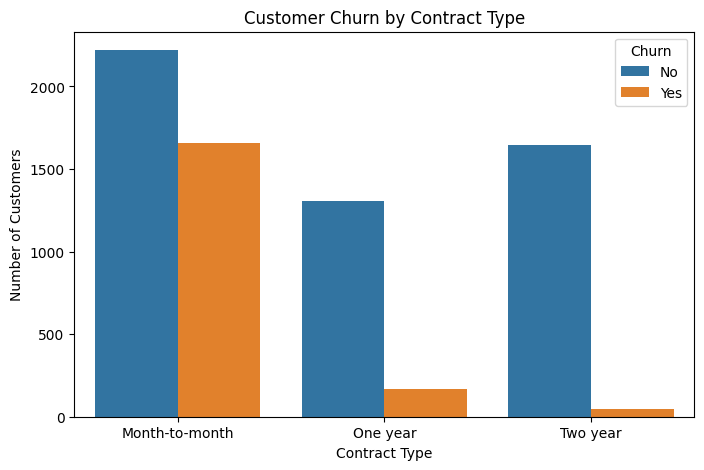

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()


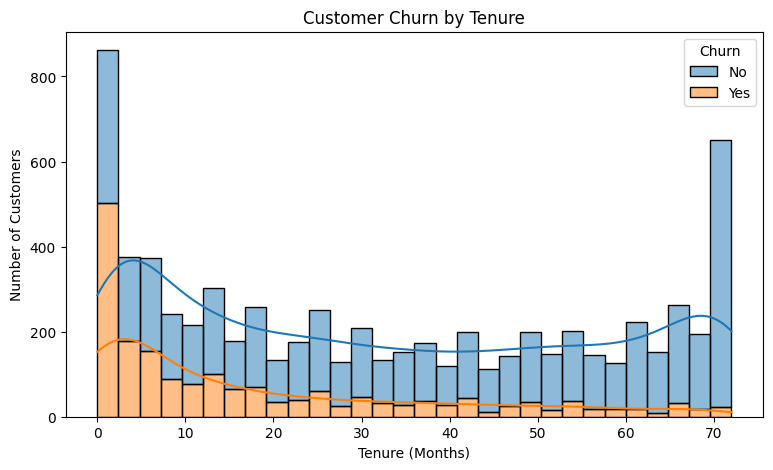

In [14]:

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='tenure', hue='Churn',
             bins=30, kde=True, multiple='stack')

plt.title('Customer Churn by Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()


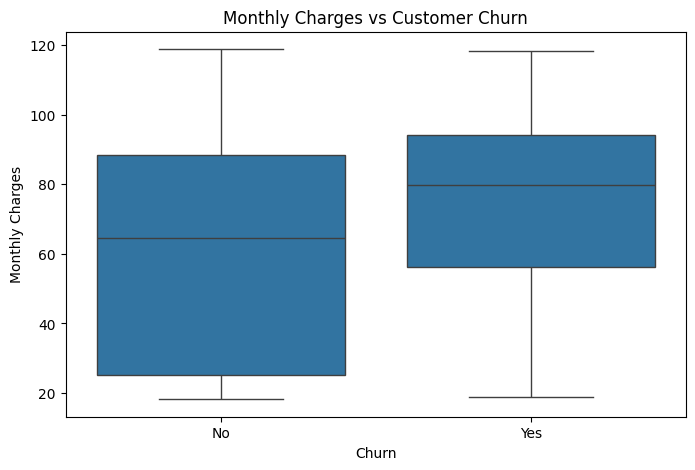

In [15]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()


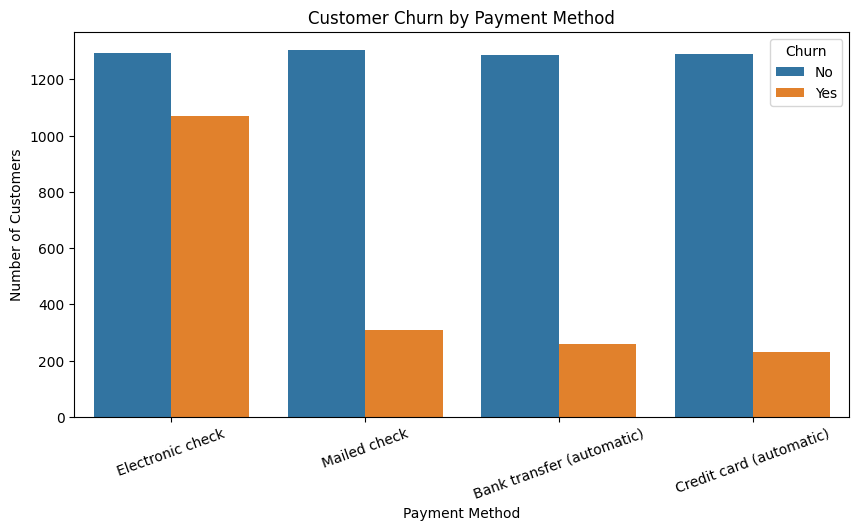

In [16]:

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='PaymentMethod', hue='Churn')

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.show()



### Key Findings

**1. Churn by Contract Type**

Month-to-month customers have the highest churn rate of 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts. This indicates that customers with shorter contracts are more likely to leave the company.

**2. Churn by Payment Method**

Customers using electronic checks have the highest churn rate at 45.29%. In comparison, customers using automatic bank transfers and credit card payments have churn rates of 16.71% and 15.24%, respectively.

**3. Churn by Tenure**

Customers who leave the company have an average tenure of 17.98 months, while customers who stay have an average tenure of 37.57 months. This suggests that newer customers are more vulnerable to churn.

**4. Churn by Monthly Charges**

Customers who churn have average monthly charges of 74.44, compared with 61.27 for customers who remain. This suggests that higher monthly charges may be associated with an increased likelihood of churn.

### EDA Conclusion

The analysis indicates that contract type, customer tenure, payment method, and monthly charges are important factors associated with customer churn. Month-to-month customers, customers with shorter tenure, electronic check users, and customers with higher monthly bills represent important groups for customer retention strategies.

These findings will help guide the development of business recommendations later in the project.


#Train Test Split

In [18]:

# Separate input features and target variable
X = df.drop('Churn', axis=1)
y = df['Churn']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (7043, 19)
Target Shape: (7043,)


In [19]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target: (5634,)
Testing Target: (1409,)


In [20]:

print("Training Churn Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Churn Distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing Churn Distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64



## Train-Test Split

The cleaned dataset was divided into input features (X) and the target variable (y). The `Churn` column was selected as the target variable because the objective is to predict whether a customer will leave the company.

The dataset was split into 80% training data and 20% testing data using the `train_test_split()` function.

The training set contains 5,634 records, while the testing set contains 1,409 records.

The `stratify=y` parameter was used to maintain the original class distribution in both datasets. The training and testing sets contain approximately 73.46% non-churning customers and 26.54% churning customers.

A random state of 42 was used to ensure reproducibility.


#Preprocessing Pipeline

In [21]:

# Identify numerical columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))


Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Numerical Features: 4
Total Categorical Features: 15


In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")


Preprocessing Pipeline Created Successfully!


In [23]:

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:", X_train_processed.shape)
print("Testing Data After Preprocessing:", X_test_processed.shape)


Training Data After Preprocessing: (5634, 45)
Testing Data After Preprocessing: (1409, 45)



## Data Preprocessing Pipeline

Data preprocessing was performed to prepare the input features for machine learning algorithms.

The 19 input features were divided into 4 numerical features and 15 categorical features.

StandardScaler was applied to numerical features to standardize their values, while OneHotEncoder was used to convert categorical features into numerical binary representations.

A ColumnTransformer was created to combine both preprocessing operations into a single preprocessing pipeline.

The pipeline was fitted using the training data and then applied to both training and testing datasets.

After preprocessing, the training dataset was transformed into 5,634 rows and 45 features, while the testing dataset contained 1,409 rows and 45 features.

The number of features increased from 19 to 45 because categorical variables were expanded into multiple binary columns through one-hot encoding.


#Model Comparison

In [24]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Define models
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    )
}

# Store model results
results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    # Create pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label='Yes')
    recall = recall_score(y_test, y_pred, pos_label='Yes')
    f1 = f1_score(y_test, y_pred, pos_label='Yes')

    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    trained_models[name] = pipeline

# Display comparison
results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
print("=" * 70)
display(results_df.round(4))


MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136
1,Decision Tree,0.7282,0.4878,0.4813,0.4845
2,Random Forest,0.7842,0.6232,0.4733,0.5380


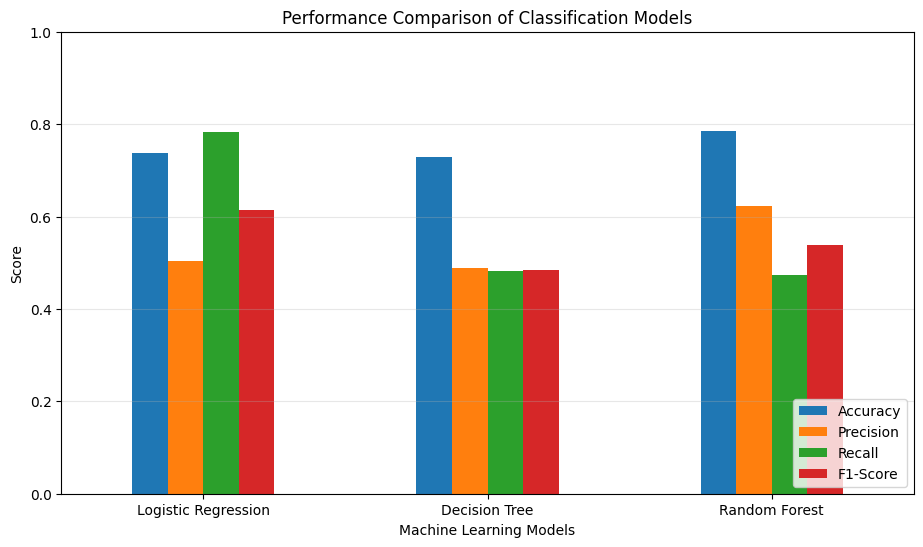

In [25]:

# Plot model comparison
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Performance Comparison of Classification Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()



## Step 7: Model Comparison

Three classification algorithms were trained and evaluated: Logistic Regression, Decision Tree, and Random Forest.

Logistic Regression achieved the highest recall of 78.34% and the highest F1-score of 61.36%. Random Forest achieved the highest accuracy of 78.42%, but its recall was considerably lower.

Since identifying potential churners is the primary objective of this project, Logistic Regression was selected as the best candidate for further optimization.

Although Random Forest performed better in terms of accuracy and precision, Logistic Regression is more suitable for this business problem because it identifies a larger proportion of customers who actually leave the company.


#Recall Optimization

In [26]:

from sklearn.metrics import classification_report

# Get Logistic Regression model
best_model = trained_models['Logistic Regression']

# Generate predictions
y_pred_lr = best_model.predict(X_test)

# Display classification report
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(y_test, y_pred_lr))


LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



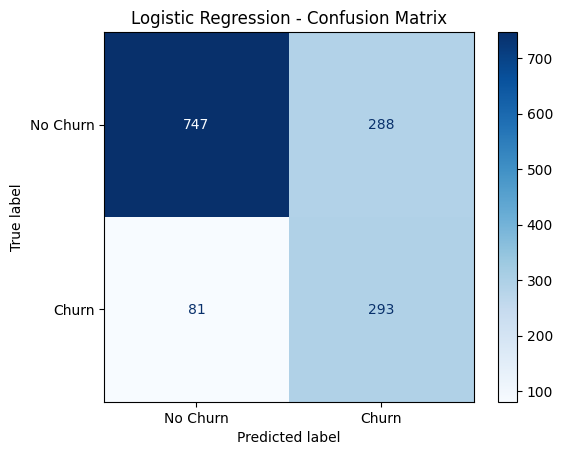

In [27]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr, labels=['No', 'Yes'])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Logistic Regression - Confusion Matrix')
plt.show()


#Hyperparameter tuning

In [32]:

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score

# Explicitly set "Yes" as the positive class
churn_recall = make_scorer(recall_score, pos_label='Yes')

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

# Parameters to test
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['lbfgs', 'liblinear'],
    'classifier__class_weight': ['balanced']
}

# Grid Search using churn recall
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring=churn_recall,
    n_jobs=-1,
    verbose=1
)

# Train and tune the model
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(round(grid_search.best_score_, 4))


# Save the optimized model
best_model = grid_search.best_estimator_

# Display a clean summary
print("OPTIMIZED LOGISTIC REGRESSION")
print("=" * 40)
print("Best Parameters:", grid_search.best_params_)
print("Cross-Validation Recall:", round(grid_search.best_score_, 4))
print("Model Status: Successfully Trained")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Best Cross-Validation Recall:
0.8047
OPTIMIZED LOGISTIC REGRESSION
Best Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Cross-Validation Recall: 0.8047
Model Status: Successfully Trained


#Final Evaluation

FINAL MODEL PERFORMANCE
Accuracy:  0.7381
Precision: 0.5043
Recall:    0.7834
F1-Score:  0.6136

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



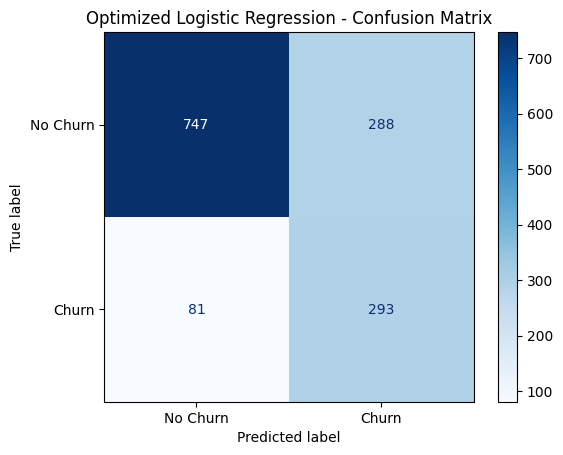

In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Make predictions using optimized model
y_pred_final = best_model.predict(X_test)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred_final)
precision = precision_score(y_test, y_pred_final, pos_label='Yes')
recall = recall_score(y_test, y_pred_final, pos_label='Yes')
f1 = f1_score(y_test, y_pred_final, pos_label='Yes')

# Display results
print("FINAL MODEL PERFORMANCE")
print("=" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 40)
print(classification_report(y_test, y_pred_final))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_final, labels=['No', 'Yes'])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Optimized Logistic Regression - Confusion Matrix")
plt.show()



## 11. Business Recommendations

Based on the exploratory data analysis and machine learning results, the following recommendations can help reduce customer churn.

### 1. Encourage Long-Term Contracts
Customers with month-to-month contracts have a churn rate of **42.71%**, compared with **11.27%** for one-year contracts and **2.83%** for two-year contracts.

**Recommendation:** Offer discounts, loyalty rewards, and other incentives to encourage customers to switch to long-term contracts.

### 2. Improve Electronic Check Payment Experience
Customers using electronic checks have a churn rate of **45.29%**, which is considerably higher than other payment methods.

**Recommendation:** Encourage customers to use automatic bank transfers or credit card payments by offering convenient payment options and incentives.

### 3. Focus on New Customers
Customers who churned had an average tenure of **17.98 months**, while customers who stayed had an average tenure of **37.57 months**.

**Recommendation:** Introduce an onboarding program, regular follow-ups, and special offers to improve customer engagement during the early months.

### 4. Review Monthly Charges
Customers who churned had average monthly charges of **$74.44**, compared with **$61.27** for customers who stayed.

**Recommendation:** Review pricing plans and offer affordable packages, personalized discounts, and bundled services to improve customer satisfaction.

### Conclusion

The Telecom Customer Churn Predictor uses Logistic Regression to identify customers who may leave the company.

The optimized model achieved **73.81% accuracy**, **78.34% churn recall**, and a **61.36% F1-score** on the test dataset.

The findings can help telecom businesses identify potentially dissatisfied customers, prioritize retention campaigns, and make more informed business decisions.


#Saving Model and Streamlit

In [34]:

import joblib

# Save the complete optimized pipeline
joblib.dump(best_model, 'churn_model.joblib')

print("Model saved successfully!")
print("File: churn_model.joblib")


Model saved successfully!
File: churn_model.joblib


In [35]:

from google.colab import files

files.download('churn_model.joblib')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("churn_model.joblib")

# Page configuration
st.set_page_config(
    page_title="Telecom Customer Churn Predictor",
    page_icon="📊",
    layout="centered"
)

# Application title
st.title("📊 Telecom Customer Churn Predictor")
st.write(
    "Enter customer information below to predict "
    "whether the customer is likely to leave the telecom company."
)

st.divider()

# Customer information form
st.header("Customer Information")

with st.form("customer_form"):

    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        senior = st.selectbox("Senior Citizen", [0, 1])
        partner = st.selectbox("Has Partner?", ["Yes", "No"])
        dependents = st.selectbox("Has Dependents?", ["Yes", "No"])
        tenure = st.number_input("Tenure (Months)", 0, 72, 12)

        phone_service = st.selectbox("Phone Service", ["Yes", "No"])
        multiple_lines = st.selectbox(
            "Multiple Lines",
            ["No", "Yes", "No phone service"]
        )

        internet_service = st.selectbox(
            "Internet Service",
            ["DSL", "Fiber optic", "No"]
        )

        online_security = st.selectbox(
            "Online Security",
            ["Yes", "No", "No internet service"]
        )

    with col2:
        online_backup = st.selectbox(
            "Online Backup",
            ["Yes", "No", "No internet service"]
        )

        device_protection = st.selectbox(
            "Device Protection",
            ["Yes", "No", "No internet service"]
        )

        tech_support = st.selectbox(
            "Tech Support",
            ["Yes", "No", "No internet service"]
        )

        streaming_tv = st.selectbox(
            "Streaming TV",
            ["Yes", "No", "No internet service"]
        )

        streaming_movies = st.selectbox(
            "Streaming Movies",
            ["Yes", "No", "No internet service"]
        )

        contract = st.selectbox(
            "Contract",
            ["Month-to-month", "One year", "Two year"]
        )

        paperless_billing = st.selectbox(
            "Paperless Billing",
            ["Yes", "No"]
        )

        payment_method = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )

    monthly_charges = st.number_input(
        "Monthly Charges ($)",
        min_value=0.0,
        value=70.0,
        step=1.0
    )

    total_charges = st.number_input(
        "Total Charges ($)",
        min_value=0.0,
        value=840.0,
        step=1.0
    )

    submitted = st.form_submit_button(
        "Predict Customer Churn",
        use_container_width=True
    )

# Prediction
if submitted:

    customer_data = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges
    }])

    prediction = model.predict(customer_data)[0]

    # Get probability for the churn class
    churn_index = list(model.classes_).index("Yes")
    churn_probability = model.predict_proba(customer_data)[0][churn_index]

    st.divider()
    st.header("Prediction Result")

    st.metric(
        "Estimated Churn Probability",
        f"{churn_probability * 100:.2f}%"
    )

    st.progress(float(churn_probability))

    if prediction == "Yes":
        st.error("⚠️ This customer is predicted to CHURN.")

        if churn_probability >= 0.70:
            st.subheader("Risk Level: High")
        elif churn_probability >= 0.40:
            st.subheader("Risk Level: Medium")
        else:
            st.subheader("Risk Level: Low")

        st.info(
            "Recommendation: Contact this customer, review their "
            "pricing plan, and consider personalized retention offers."
        )

    else:
        st.success("✅ This customer is predicted to STAY.")

        st.info(
            "Recommendation: Continue providing good service and "
            "maintain customer engagement."
        )


Writing app.py


In [37]:

%%writefile requirements.txt

streamlit
pandas
scikit-learn
joblib


Writing requirements.txt


In [41]:

import zipfile

files_to_zip = [
    "app.py",
    "churn_model.joblib",
    "requirements.txt"
]

with zipfile.ZipFile("Telecom_Churn_Project.zip", "w") as zipf:
    for file in files_to_zip:
        zipf.write(file)

from google.colab import files
files.download("Telecom_Churn_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>